# Residuales e identificabilidad en un modelo gravimétrico de dos celdas

**Pregunta:** Para dos celdas verticales contiguas y una línea superficial, ¿la matriz de sensibilidad ponderada contiene información independiente suficiente para resolver ambos contrastes?

**Nivel 2 · Prerrequisitos: la lección previa de fundamentos; lectura estimada: 50 minutos.**

## Objetivos

Calcular residuales y jacobiano ponderado de dos celdas; examinar direcciones singulares y límites de identificabilidad local.

## Preparación

Use el entorno Python 3.12 fijado. Créelo desde la raíz con `scripts/setup.ps1 -Notebooks` en Windows o `scripts/setup.sh --notebooks` en Linux/macOS. El comando se documenta como referencia; el notebook no instala paquetes.

```text
pip install simpeg==0.25.2 geoana==0.8.1 discretize==0.12.0
```

Importar una vez el método y herramientas gráficas. La celda informa implementación activa.

In [1]:
# Importar métodos del repositorio y herramientas gráficas.
from importlib.metadata import version
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
root = Path.cwd().parents[2]
sys.path.insert(0, str(root / 'data-pipeline'))
import gravity_forward
print('Motor:', gravity_forward.ENGINE)


Motor: simpeg-0.25.2-geoana-0.8.1-f64-ram


## Datos

Esta lección construye un control sintético compacto: dos celdas contiguas de 100 m, 41 estaciones exteriores y desviación estándar explícita de 0,05 mGal por estación. La desviación es un supuesto experimental, no incertidumbre medida. El operador directo `gravity_forward.forward_gravity` evalúa de nuevo respuesta y jacobiano en este kernel. No se leen resultados de inversión guardados. El control sintético es material original del producto Apache-2.0 y no representa datos de campo.

Leer entradas declaradas o construir geometría sintética propia. No se carga salida de solver.

In [2]:
# Definir columna sintética de dos capas y línea superficial exterior.
mesh = {'origin_m': np.array([-50., -50., -300.]), 'hx_m': np.array([100.]),
        'hy_m': np.array([100.]), 'hz_m': np.array([100., 100.]),
        'active': np.array([True, True])}
x = np.linspace(-500., 500., 41)
receivers = np.column_stack([x, np.zeros_like(x), np.zeros_like(x)])
base = {'schema': 'gravity-prism-forward-request-1',
        'frame': dict(gravity_forward.FRAME), 'mesh': mesh,
        'receivers_m': receivers, 'engine': gravity_forward.ENGINE}
print('Celdas:', len(mesh['active']), '| estaciones:', len(receivers))


Celdas: 2 | estaciones: 41


## Método

### El residual conserva unidades y signo

Para observación d y predicción F(m), definimos r=d−F(m). El residual con signo indica subpredicción o sobrepredicción; RMSE elimina signo y mantiene mGal. En este ejercicio sintético generamos observaciones con el mismo operador declarado y luego añadimos una perturbación alternada determinista. Así se pueden seguir los cálculos sin presentar una realización de ruido como medida de campo.

### Blanquear declara un supuesto de ruido

Con desviaciones independientes σᵢ, el residual ponderado es Wᵈr, con Wᵈ=diag(1/σᵢ). El término de mínimos cuadrados ponderados es ½‖Wᵈr‖². El blanqueo cambia el peso relativo de cada fila según la incertidumbre declarada. No corrige errores correlacionados, sesgo sistemático, campo regional incompleto ni covarianza incorrecta. Aquí σ constante es un control didáctico explícito.

### La sensibilidad depende del modelo y geometría

El operador del producto devuelve un jacobiano J en mGal por kg/m³. Sus columnas son los cambios de datos por unidad de densidad en cada celda activa. Formamos WᵈJ y examinamos sus valores singulares. Rango dos indica columnas numéricamente independientes bajo el umbral elegido; un segundo valor pequeño señala una dirección débil. El rango numérico depende del umbral y no es resolución geológica.

### Una dirección nula cambia poco el modelo

El vector singular derecho asociado al menor valor singular combina contrastes de celda con escaso cambio ponderado en datos. Sumar una amplitud moderada de ese vector a un modelo de referencia crea dos alternativas concretas. La diferencia de predicción, no la apariencia de un dibujo, prueba si este levantamiento distingue las alternativas.

### Holdout y ajuste responden preguntas distintas

Un residual calculado sobre la misma línea sintética mide compatibilidad con esos valores. Una línea retenida o bloque espacial prueba transferencia a ubicaciones no usadas para ajustar; esta lección no ejecuta una inversa ni afirma validación externa. La segunda figura informa espectro de sensibilidad y cambio entre modelos para mostrar evidencia disponible y ausente.

### Lo que la incertidumbre no incluye

La aproximación de covarianza Cₘ≈(JᵀCᵈ⁻¹J+βR)⁻¹ depende de linealización local, regularizador R y β. Omite incertidumbre geométrica, selección de modelos, error estructural y alternativas geológicas salvo que se representen explícitamente. Este notebook no informa probabilidades posteriores ni deduce intervalos de confianza de un único supuesto de ruido.

### Interpretar con cuidado un residual pequeño

Un RMSE bajo puede coexistir con sensibilidad casi deficiente en rango: los datos se ajustan mientras sigue siendo plausible una familia de modelos. A la inversa, un modelo didáctico identificable de dos parámetros no implica que un modelo terrestre realista lo sea. Informe unidades, sigma, dimensiones de matriz, umbral y parametrización juntos para hacer reproducible qué significa “resuelto”.

Ejecutar método directo con contraste unitario en celda superior. Su columna jacobiana es una dirección de sensibilidad.

In [3]:
# Evalúe el método del producto para la celda superior.
superior_result = gravity_forward.forward_gravity({**base, 'density_kg_m3': np.array([0.0, 100.0])})
print('resultado_superior centro mGal:', float(superior_result['gz_up_mgal'][len(x) // 2]))

resultado_superior centro mGal: -0.02927236040238318


Repetir para celda inferior conservando orden y geometría.

In [4]:
# Evalúe el método del producto para la celda inferior.
inferior_result = gravity_forward.forward_gravity({**base, 'density_kg_m3': np.array([100.0, 0.0])})
print('resultado_inferior centro mGal:', float(inferior_result['gz_up_mgal'][len(x) // 2]))

resultado_inferior centro mGal: -0.010659464525418208


Calcular desde cero modelo de referencia de dos celdas; define observaciones sintéticas.

In [5]:
# Evalúe el método del producto para el modelo de referencia.
truth_result = gravity_forward.forward_gravity({**base, 'density_kg_m3': np.array([40.0, 80.0])})
print('resultado_verdad centro mGal:', float(truth_result['gz_up_mgal'][len(x) // 2]))

resultado_verdad centro mGal: -0.027681674132073827


Evaluar modelo distinto para probar dirección finita de no unicidad con igual operador.

In [6]:
# Evalúe el método del producto para el modelo alternativo.
alternative_result = gravity_forward.forward_gravity({**base, 'density_kg_m3': np.array([70.0, 65.0])})
print('resultado_alternativo centro mGal:', float(alternative_result['gz_up_mgal'][len(x) // 2]))

resultado_alternativo centro mGal: -0.026488659429341813


Ejecutar segundo modelo unitario. Su jacobiano entrega matriz independiente para comparar consistencia.

In [7]:
# Evalúe el método del producto con contraste unitario.
unit_result = gravity_forward.forward_gravity({**base, 'density_kg_m3': np.array([1.0, 1.0])})
print('resultado_unitario centro mGal:', float(unit_result['gz_up_mgal'][len(x) // 2]))

resultado_unitario centro mGal: -0.0003993182492780139


Formar realización de ruido y residual con signo para modelo alternativo. Sigma es supuesto experimental, no inferido por solver.

In [8]:
# Generar observaciones sintéticas deterministas y revisar sensibilidad ponderada.
sigma_mgal = 0.05
noise = 0.03 * np.where(np.arange(len(x)) % 2 == 0, 1.0, -1.0)
observed = truth_result['gz_up_mgal'] + noise
residual = observed - alternative_result['gz_up_mgal']
J = truth_result['jacobian_mgal_per_kg_m3']
weighted_J = J / sigma_mgal
u, singular_values, vh = np.linalg.svd(weighted_J, full_matrices=False)
rank = int(np.linalg.matrix_rank(weighted_J))
rmse = float(np.sqrt(np.mean(residual ** 2)))
print({'rmse_mgal': rmse, 'range': rank, 'valores_singulares': singular_values.tolist()})

{'rmse_mgal': 0.03000835555409876, 'range': 2, 'valores_singulares': [0.017207450046458773, 0.001803831511375517]}


El primer panel compara observaciones sintéticas, predicción de referencia y predicción después de desplazarse por la dirección menos sensible. El segundo conserva residuales con signo en mGal. Muestra la relación entre ajuste y separación de modelos en este ejemplo construido. No es mapa de residuales de campo, resultado inverso ni incertidumbre adicional a la perturbación alternada declarada.

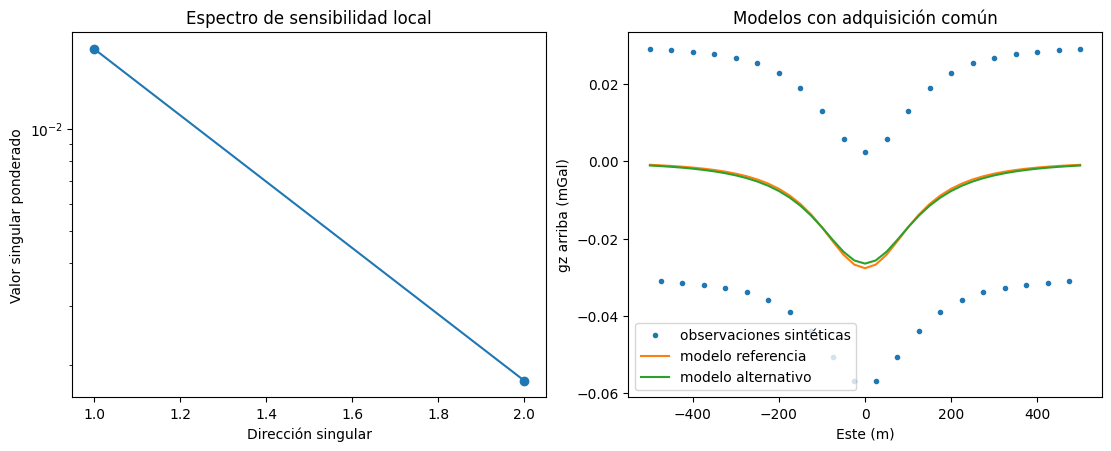

In [9]:
# Graficar valores singulares ponderados y predicciones calculadas.
fig, (ax, bx) = plt.subplots(1, 2, figsize=(11, 4.4), constrained_layout=True)
ax.semilogy(np.arange(1, len(singular_values) + 1), singular_values, 'o-')
ax.set(xlabel='Dirección singular', ylabel='Valor singular ponderado', title='Espectro de sensibilidad local')
bx.plot(x, observed, '.', label='observaciones sintéticas')
bx.plot(x, truth_result['gz_up_mgal'], label='modelo referencia')
bx.plot(x, alternative_result['gz_up_mgal'], label='modelo alternativo')
bx.set(xlabel='Este (m)', ylabel='gz arriba (mGal)', title='Modelos con adquisición común')
bx.legend()
plt.show()

El panel de valores singulares usa el jacobiano del producto dividido por los errores declarados de 0,05 mGal. Espectro y rango numérico cuantifican sensibilidad local para dos parámetros de celda y esta línea de estaciones. El panel de pares comprueba el cambio con el operador directo. Nada de esto demuestra unicidad fuera de esta malla, geometría o modelo de ruido.

Graficar residuales con signo y banda de una sigma. Secuencias fuera cuestionarían errores independientes y de media cero; esta perturbación didáctica no calibra un umbral empírico.

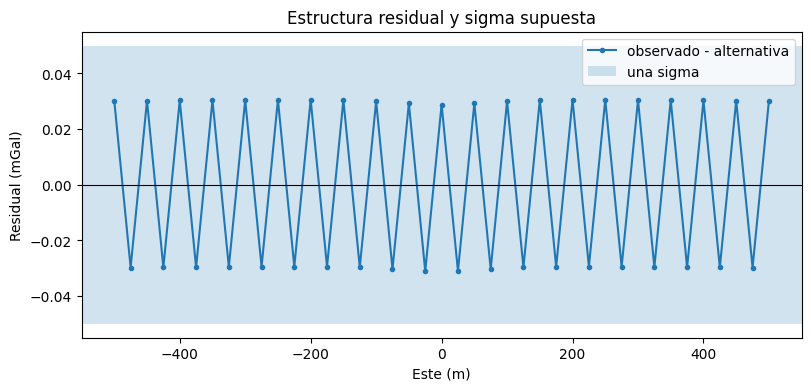

In [10]:
# Revisar signo residual frente a escala de error independiente.
fig, ax = plt.subplots(figsize=(8, 3.8), constrained_layout=True)
ax.plot(x, residual, marker='.', label='observado - alternativa')
ax.axhspan(-sigma_mgal, sigma_mgal, alpha=0.2, label='una sigma')
ax.axhline(0.0, color='black', linewidth=0.8)
ax.set(xlabel='Este (m)', ylabel='Residual (mGal)', title='Estructura residual y sigma supuesta')
ax.legend()
plt.show()

Cada marcador conserva identidad de estación y residual con signo; la banda representa la desviación estándar supuesta. Un patrón espacial persistente podría señalar sesgo o estructura no modelada que RMSE oculta. Aquí la perturbación es determinista y construida para enseñar el cálculo: cruzar la banda no tiene interpretación probabilística. La banda no es umbral empírico ni incorpora covarianza.

## Resultados

**Respuesta:** El Jacobiano ponderado tiene rango numérico 2 para estas dos celdas, pero eso solo indica dos direcciones localmente independientes bajo el umbral elegido. El valor singular menor es 0.001804 frente a 0.017207, y el modelo alternativo obtiene RMSE 0.0300 mGal, por debajo de la σ supuesta de 0.05 mGal. Por tanto, el rango completo no demuestra que ambos contrastes queden resueltos al nivel de ruido; esta adquisición sintética no distingue concluyentemente esos modelos.

In [11]:
# Informar rango, error residual y escala de incertidumbre explícita.
print({'rango_ponderado': rank, 'rmse_alternativa_mgal': rmse,
       'sigma_ruido_mgal': sigma_mgal, 'forma_jacobiano': J.shape})

{'rango_ponderado': 2, 'rmse_alternativa_mgal': 0.03000835555409876, 'sigma_ruido_mgal': 0.05, 'forma_jacobiano': (41, 2)}


## Resumen

Los residuales describen error predictivo bajo una convención explícita; los valores singulares describen sensibilidad local según parametrización y ponderación. Juntos revelan direcciones débilmente resueltas aunque el ajuste sea pequeño. Este análisis sintético de dos celdas es diagnóstico, no inversión de campo aceptada.

## Referencias

- https://doi.org/10.1016/j.cageo.2015.09.015